# Imports

In [1]:
import torch
import sys
import os
import seaborn as sns
from torch import Tensor
from torch_scatter import scatter
sys.path.append('..')
from src.commands.feature_extraction import Graph
from typing import Dict
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objs as go
from functools import partial
from definitions import EXPERIMENTS_DIR
from src.commands.train import Trainer, Config
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputClassifier
from sklearn.manifold import TSNE
from sklearn.model_selection import KFold
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, ClassifierMixin
from torch_geometric import utils as gnn_utils
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    hamming_loss,
)

/home/fellah-a/anaconda3/envs/text2kg-main/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
px.defaults.template = 'seaborn'

In [3]:
# Source - https://stackoverflow.com/a/33616192
# Posted by joshterrell805, modified by community. See post 'Timeline' for change history
# Retrieved 2026-06-01, License - CC BY-SA 3.0

def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

#... import sklearn stuff...

In [4]:
graph = Graph.load('/home/fellah-a/Documents/Text2KG/data/features/nantes_uni_2020_2026_e5')

# Load The results

In [5]:
EXPERIMENT = 'nantes-uni-2020_e5_ssl'
CORPUS = 'nantes-uni-2020'
EXPERIMENT_DIR = os.path.join(EXPERIMENTS_DIR, EXPERIMENT)
RESULTS_DIR = os.path.join(EXPERIMENT_DIR, 'results')
HISTORIES_DIR = os.path.join(EXPERIMENT_DIR, 'histories')
CONFIG_PATH = os.path.join(EXPERIMENT_DIR, 'config.json')
SPLIT_PATH = os.path.join(EXPERIMENT_DIR, 'split_sub_dsis_4.pt')

In [6]:
history = pd.concat([
    pd.read_csv(os.path.join(HISTORIES_DIR, filename))
    for filename in os.listdir(HISTORIES_DIR)
])
history = history \
    .groupby(['epoch','phase','config']) \
    .mean() \
    .reset_index()
history.head()

,epoch,phase,config,l1,structure_rec_loss,loss,l2,rec_loss,margin_structure_rec_loss
0,0,train,Conv_Mean,0.169854,NaN,0.169854,NaN,NaN,NaN
1,0,train,Conv_Mean_Aug,0.176095,NaN,0.176095,NaN,NaN,NaN
2,0,train,Conv_Mean_Dual,0.096518,NaN,2.968997,2.872479,NaN,NaN
3,0,train,Conv_Mean_Dual_Aug,3.298377,NaN,3.298377,3.179811,NaN,NaN
4,0,train,Conv_Mean_Margin_Structure,0.550133,NaN,0.550133,NaN,NaN,0.340495


In [7]:
history_mean = history \
    .drop(columns = 'trial', errors="ignore") \
    .groupby(['epoch','phase','config']).mean() \
    .add_suffix('_mean')

history_std = history \
    .drop(columns = 'trial', errors="ignore") \
    .groupby(['epoch','phase','config']).std() \
    .add_suffix('_std')

In [8]:
history = history_mean.join(other = history_std).reset_index()
history.head(6)

,epoch,phase,config,l1_mean,structure_rec_loss_mean,loss_mean,l2_mean,rec_loss_mean,margin_structure_rec_loss_mean,l1_std,structure_rec_loss_std,loss_std,l2_std,rec_loss_std,margin_structure_rec_loss_std
0,0,train,Conv_Mean,0.169854,NaN,0.169854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,train,Conv_Mean_Aug,0.176095,NaN,0.176095,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,train,Conv_Mean_Dual,0.096518,NaN,2.968997,2.872479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,train,Conv_Mean_Dual_Aug,3.298377,NaN,3.298377,3.179811,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,train,Conv_Mean_Margin_Structure,0.550133,NaN,0.550133,NaN,NaN,0.340495,NaN,NaN,NaN,NaN,NaN,NaN
5,0,train,Conv_Mean_Margin_Structure_2,0.540012,NaN,0.540012,NaN,NaN,0.336586,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
history.tail(6)

,epoch,phase,config,l1_mean,structure_rec_loss_mean,loss_mean,l2_mean,rec_loss_mean,margin_structure_rec_loss_mean,l1_std,structure_rec_loss_std,loss_std,l2_std,rec_loss_std,margin_structure_rec_loss_std
214,9,val,Conv_Mean_Margin_Structure_2,0.136634,NaN,0.136634,NaN,NaN,0.116083,NaN,NaN,NaN,NaN,NaN,NaN
215,9,val,Conv_Mean_Rec,0.022024,NaN,0.022024,NaN,0.012255,NaN,NaN,NaN,NaN,NaN,NaN,NaN
216,9,val,Conv_Mean_Rec_Dual,1.139707,NaN,1.139707,1.110528,0.024370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
217,9,val,Conv_Mean_Rec_Dual_2,1.121484,NaN,1.121484,1.109965,0.006663,NaN,NaN,NaN,NaN,NaN,NaN,NaN
218,9,val,Conv_Mean_Structure_Rec,0.367538,0.334322,0.367538,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
219,9,val,Conv_Mean_Structure_Rec_2,0.365869,0.333722,0.365869,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Load The data

In [10]:
config = Config(experiment=EXPERIMENT)
trainer = Trainer(experiment=config.experiment, config=config.training_config)
configs = trainer.get_configs()

In [11]:
data = trainer.load_data()
split = trainer.create_or_load_split(data)

In [12]:
data_path = os.path.join(RESULTS_DIR, 'predictions_Conv_Mean.pt')
embeddings = torch.load(data_path)

embeddings = {
    '_'.join(filename.split('.')[0].split('_')[1:]): torch.load(os.path.join(RESULTS_DIR, filename))
    for filename in os.listdir(RESULTS_DIR)
}

In [13]:
def display_mean_std_df(df : pd.DataFrame) -> pd.DataFrame:

    columns = set([
        col.replace('_mean','')
        for col in df.columns if 'mean' in col
    ])

    new_df = pd.DataFrame()

    for col in df.columns:

        if not col.endswith('_mean') and not col.endswith('_std'):
            new_df[col] = df[col]

    for col in columns:
        new_df[col] = df[f'{col}_mean'].apply(lambda x : f'{x:.2%}') + ' ± ' + df[f'{col}_std'].apply(lambda x : f'{x:.2%}')

    return new_df

In [14]:
def train_and_evaluate(
    features : Dict[str, Tensor],
    split : Tensor,
    labels : Tensor
) -> pd.DataFrame:
    
    labels = labels.numpy()
    models = [KNeighborsClassifier] #[LogisticRegression, DecisionTreeClassifier, KNeighborsClassifier]
    results = []
    
    for name, F in features.items():

        F = F.numpy()

        for trial in split.unique().tolist():

            x_train = F[split != trial,:]
            x_test = F[split == trial,:]
            y_train = labels[split != trial,:]
            y_test = labels[split == trial,:]

            for model in models:

                print(f'Config = {name} | Trial = {trial} | Model = {model.__name__}')

                pipe = Pipeline([
                    ('Preprocessor', StandardScaler()),
                    ('Estimator', MultiOutputClassifier(estimator=model()))
                ])

                pipe.fit(x_train, y_train)

                y_soft = pipe.predict_proba(x_test)
                y_soft = np.stack([y[:,1] for y in y_soft], axis=1)

                y_hard = (y_soft >= 0.5).astype(int)

                results.append({
                    "Config" : name,
                    "Trial" : trial,
                    "Model" : model.__name__,
                    "Accuracy" : accuracy_score(y_test, y_hard),
                    "Macro F1-Score" : f1_score(y_test, y_hard , average='macro', zero_division=0),
                    "Macro Precision" : precision_score(y_test, y_hard , average='macro', zero_division=0),
                    "Macro Recall" : recall_score(y_test, y_hard , average='macro', zero_division=0),
                    "Macro AUC" : roc_auc_score(y_test, y_soft , average='macro'),
                    "Hamming Loss" : hamming_loss(y_test, y_hard)
                })

    results = pd.DataFrame(results)

    mean = results.drop(columns=['Trial']).groupby(by=['Config', 'Model']).mean().add_suffix('_mean')
    std = results.drop(columns=['Trial']).groupby(by=['Config', 'Model']).std().add_suffix('_std')

    return mean.join(std).reset_index()

In [15]:
row, col = data['Entity', 'APPEARIN', 'Article'].edge_index

x = scatter(
    src=data['Entity'].x[row],
    index=col,
    dim=0,
    dim_size=data['Article'].x.shape[0],
    reduce='mean'
)

In [16]:
results = train_and_evaluate(
    features={ 
        "default" : data['Article'].x,
        "agg" : x,
        **{
            k : v['articles_embeddings_v2'] 
            for k, v in embeddings.items()
        }
    },
    split=split,
    labels=data['Article'].y_subdomain
)

Config = default | Trial = 0 | Model = KNeighborsClassifier
Config = default | Trial = 1 | Model = KNeighborsClassifier
Config = default | Trial = 2 | Model = KNeighborsClassifier
Config = default | Trial = 3 | Model = KNeighborsClassifier
Config = agg | Trial = 0 | Model = KNeighborsClassifier
Config = agg | Trial = 1 | Model = KNeighborsClassifier
Config = agg | Trial = 2 | Model = KNeighborsClassifier
Config = agg | Trial = 3 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 1 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 2 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 3 | Model = KNeighborsClassifier
Config = Conv_Mean_Rec_Dual_2 | Trial = 0 | Model = KNeighborsClassifier
Config = Conv_Mean_Rec_Dual_2 | Trial = 1 | Model = KNeighborsClassifier
Config = Conv_Mean_Rec_Dual_2 | Trial = 2 | Model = KNeighborsClassifier
Config = Conv_Mean_Rec_Dual_2 | Trial = 3 | Model

In [17]:
display_mean_std_df(results)

,Config,Model,Accuracy,Macro F1-Score,Macro Precision,Hamming Loss,Macro Recall,Macro AUC
0,Conv_Mean,KNeighborsClassifier,33.93% ± 0.98%,49.21% ± 1.61%,65.67% ± 3.32%,7.46% ± 0.20%,41.78% ± 1.21%,84.36% ± 0.37%
1,Conv_Mean_Aug,KNeighborsClassifier,33.81% ± 0.71%,47.93% ± 1.48%,64.26% ± 2.76%,7.58% ± 0.19%,40.30% ± 1.27%,83.11% ± 0.51%
2,Conv_Mean_Dual,KNeighborsClassifier,37.91% ± 0.67%,51.35% ± 1.52%,71.07% ± 3.46%,6.81% ± 0.19%,41.99% ± 1.07%,86.21% ± 0.50%
3,Conv_Mean_Dual_Aug,KNeighborsClassifier,40.67% ± 0.80%,56.79% ± 0.51%,71.10% ± 1.97%,6.23% ± 0.17%,48.70% ± 0.64%,87.38% ± 0.32%
4,Conv_Mean_Margin_Structure,KNeighborsClassifier,42.69% ± 0.96%,59.87% ± 1.82%,73.25% ± 4.34%,5.93% ± 0.16%,52.69% ± 1.42%,88.93% ± 1.07%
5,Conv_Mean_Margin_Structure_2,KNeighborsClassifier,43.05% ± 1.26%,60.02% ± 1.99%,73.47% ± 2.16%,5.91% ± 0.19%,52.55% ± 2.17%,88.89% ± 0.42%
6,Conv_Mean_Rec,KNeighborsClassifier,40.74% ± 1.39%,58.06% ± 0.74%,69.16% ± 3.65%,6.16% ± 0.18%,52.02% ± 0.73%,88.56% ± 0.30%
7,Conv_Mean_Rec_Dual,KNeighborsClassifier,38.74% ± 0.92%,52.87% ± 0.38%,71.36% ± 2.92%,6.60% ± 0.29%,43.75% ± 0.50%,86.91% ± 0.36%
8,Conv_Mean_Rec_Dual_2,KNeighborsClassifier,41.82% ± 0.53%,58.96% ± 0.47%,73.93% ± 1.39%,6.04% ± 0.13%,50.73% ± 0.18%,88.83% ± 0.59%
9,Conv_Mean_Structure_Rec,KNeighborsClassifier,40.34% ± 0.48%,56.42% ± 1.36%,71.92% ± 1.45%,6.33% ± 0.17%,48.03% ± 1.15%,87.52% ± 0.46%


# Entity Level

In [18]:
row, col = data['Entity', 'APPEARIN', 'Article'].edge_index

y = scatter(
    src=data['Article'].y_subdomain[col],
    index=row,
    dim=0,
    dim_size=data['Entity'].x.shape[0],
    reduce='mean'
)

x = scatter(
    src=data['Article'].x[col,:],
    index=row,
    dim=0,
    dim_size=data['Entity'].x.shape[0],
    reduce='mean'
)

mask = gnn_utils.degree(row, num_nodes=data['Entity'].x.shape[0]).ge(3)
y = (y >= 0.5).float()

y = y[mask,:]

kfold = KFold(n_splits=4, shuffle=True)
e_split = torch.zeros_like(y[:,0])

for i, (_, test_ids) in enumerate(kfold.split(y)):
    test_ids = torch.from_numpy(test_ids).to(e_split).long()
    e_split[test_ids] = i

results = train_and_evaluate(
    features={
        "default" : data['Entity'].x[mask,:],
        "agg" : x[mask,:],
        **{ 
            k : v['entities_embeddings_v1'][mask,:]
            for k, v in embeddings.items()
        }
    },
    split=e_split,
    labels=y
)

Config = default | Trial = 0.0 | Model = KNeighborsClassifier
Config = default | Trial = 1.0 | Model = KNeighborsClassifier
Config = default | Trial = 2.0 | Model = KNeighborsClassifier
Config = default | Trial = 3.0 | Model = KNeighborsClassifier
Config = agg | Trial = 0.0 | Model = KNeighborsClassifier
Config = agg | Trial = 1.0 | Model = KNeighborsClassifier
Config = agg | Trial = 2.0 | Model = KNeighborsClassifier
Config = agg | Trial = 3.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 0.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 1.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 2.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 3.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Rec_Dual_2 | Trial = 0.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Rec_Dual_2 | Trial = 1.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Rec_Dual_2 | Trial = 2.0 | Model = KNeighborsClassifier
Config = Conv_Mean_

In [19]:
display_mean_std_df(results)

,Config,Model,Accuracy,Macro F1-Score,Macro Precision,Hamming Loss,Macro Recall,Macro AUC
0,Conv_Mean,KNeighborsClassifier,26.39% ± 0.64%,28.85% ± 2.65%,58.46% ± 7.17%,8.00% ± 0.16%,21.27% ± 1.84%,73.05% ± 1.05%
1,Conv_Mean_Aug,KNeighborsClassifier,26.47% ± 0.84%,28.50% ± 1.40%,61.60% ± 6.13%,7.99% ± 0.14%,20.89% ± 0.96%,73.72% ± 1.22%
2,Conv_Mean_Dual,KNeighborsClassifier,45.75% ± 1.32%,56.27% ± 1.44%,79.27% ± 1.53%,5.08% ± 0.14%,45.79% ± 1.24%,86.71% ± 0.88%
3,Conv_Mean_Dual_Aug,KNeighborsClassifier,45.50% ± 0.53%,58.70% ± 1.35%,78.12% ± 1.86%,5.02% ± 0.13%,48.92% ± 1.17%,88.03% ± 1.03%
4,Conv_Mean_Margin_Structure,KNeighborsClassifier,26.82% ± 1.26%,30.61% ± 2.24%,63.91% ± 5.73%,7.85% ± 0.11%,22.15% ± 1.43%,73.23% ± 0.57%
5,Conv_Mean_Margin_Structure_2,KNeighborsClassifier,26.94% ± 1.36%,31.61% ± 0.96%,68.35% ± 5.35%,7.84% ± 0.18%,23.04% ± 0.63%,73.69% ± 0.79%
6,Conv_Mean_Rec,KNeighborsClassifier,29.02% ± 0.84%,34.22% ± 1.25%,67.20% ± 3.20%,7.38% ± 0.08%,25.15% ± 0.84%,76.73% ± 0.41%
7,Conv_Mean_Rec_Dual,KNeighborsClassifier,45.62% ± 1.03%,56.71% ± 1.34%,79.27% ± 2.59%,5.07% ± 0.08%,46.40% ± 1.27%,87.52% ± 1.95%
8,Conv_Mean_Rec_Dual_2,KNeighborsClassifier,45.56% ± 1.33%,56.41% ± 1.57%,78.26% ± 0.99%,5.12% ± 0.12%,45.93% ± 1.85%,86.90% ± 1.06%
9,Conv_Mean_Structure_Rec,KNeighborsClassifier,30.02% ± 0.66%,34.74% ± 1.03%,69.46% ± 3.80%,7.36% ± 0.13%,25.49% ± 0.72%,76.23% ± 1.68%


In [20]:
def search(
    graph : Graph,
    X : Tensor,
    entity : str,
    k : int = 5
) -> list[str]:
    
    nn = NearestNeighbors().fit(X)
    
    e_id = graph._nodes['Entity']._id2idx[entity]

    scores, ind = nn.kneighbors(X[[e_id],:], n_neighbors=k+1)
    ind = ind[0][1:].tolist()
    scores = scores[0][1:].tolist()

    entities = []

    for i, score in zip(ind, scores):
        entities.append(graph._nodes['Entity']._nodes[i].id)

    # entities = sorted(entities, key=lambda x : x[1])

    return entities

In [21]:
for entity in [
    'anomaly_detection',
    'named_entity_recognition',
    'virtual_reality',
    'energy_consumption',
    'self_supervised_learning',
    'clustering',
    'knowledge_graph',
    'user_centered_design',
    'object_detection',
    'federated_learning',
    'semantic_segmentation'
]:
    
    print(f"***Entity : {entity}***")

    e = search(
        graph, 
        embeddings['Conv_Mean_Margin_Structure_2']['entities_embeddings_v1'], 
        entity=entity,
        k=5
    )

    print(f"Simple (One Way Loss + Articles Realtions Margin Loss) : {e}")

    e = search(
        graph, 
        x, 
        entity=entity,
        k=5
    )

    print(f"Mean Articles : {e}")
    print("\n\n***********************************\n\n")

***Entity : anomaly_detection***
Simple (One Way Loss + Articles Realtions Margin Loss) : ['early_anomaly_detection', 'intrusion_detection', 'signal_detection', 'source_detection', 'object_detection']
Mean Articles : ['machine_learning', 'classification_performance', 'deep_learning', 'machine_learning_method', 'acoustic_emission']


***********************************


***Entity : named_entity_recognition***
Simple (One Way Loss + Articles Realtions Margin Loss) : ['character_detection', 'lf_view', 'nlp_task', 'arruda_boyce', 'script_concordance_test']
Mean Articles : ['large_language_model', 'natural_language_processing', 'specialized_domain', 'language_model', 'domain_specific_entity']


***********************************


***Entity : virtual_reality***
Simple (One Way Loss + Articles Realtions Margin Loss) : ['immersive_virtual_reality_experience', 'vr_application', 'extended_reality', 'virtual_reality_headset', 'avatar']
Mean Articles : ['virtual_environment', 'user_experience',

In [25]:
search(
    graph, 
    embeddings['Conv_Mean_Structure_Rec']['entities_embeddings_v1'], 
    entity='anomaly_detection',
    k=5
)

['intrusion_detection',
 'effective_intrusion_detection_system',
 'fraud_detection',
 'target_classification',
 'network_intrusion_detection']

In [67]:
search(
    graph, 
    x, 
    entity='semantic_segmentation',
    k=10
)

[('public_dataset', 10.691312789916992),
 ('spatial_relationship', 11.34836196899414),
 ('face_image', 11.584450721740723),
 ('deep_convolutional_neural_network', 11.89832592010498),
 ('segmentation', 11.905086517333984),
 ('quadratic_assignment_problem', 12.194783210754395),
 ('image', 12.343536376953125),
 ('computer_vision', 12.921235084533691),
 ('semantic_information', 13.283031463623047),
 ('deep_learning', 13.329719543457031)]

# Visualization

In [26]:
tsne = Pipeline([
    ('Preprocessor', StandardScaler()),
    ('Estimator', TSNE())
])

In [27]:
x2d = tsne.fit_transform(embeddings['Conv_Mean_Dual']['entities_embeddings_v1'])

<Axes: >

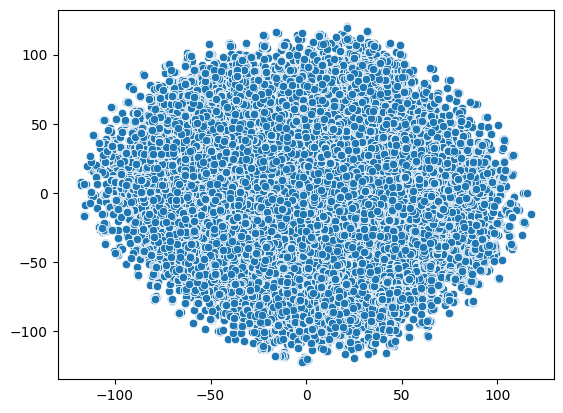

In [28]:
sns.scatterplot(
    x=x2d[:,0],
    y=x2d[:,1],
)

In [ ]:
from torch_sparse import SparseTensor
from torch.nn import functional as F

def structure_rec_loss(
    a: Tensor,
    edge_index: Tensor,
) -> Tensor:
    
    N = a.shape[0]
    
    row, col = edge_index

    A = a @ a.T
    B = SparseTensor(row=row, col=col).to_dense().to(A.device)

    L = F.binary_cross_entropy_with_logits(A, B, reduction="none")

    l_pos = L[row, col].mean()
    L[row, col] = 0.0

    l_neg = L.sum() / (N*N - len(row))

    return (l_pos + l_neg) / 2

N , M, E = 10, 16, 25

a = torch.randn((N, M))
edge_index = torch.randint(0, N, (2, E))

In [118]:
structure_rec_loss(a, edge_index)

torch.Size([10, 10]) tensor(3.6903)
tensor(2.1500) tensor(4.3184)


tensor(3.2342)

In [6]:
a

array([[-0.04570966, -0.99895477],
       [-0.48693549, -0.87343794]])

In [61]:
import numpy as np

a = np.array([[0.2, 0.7, 0.1], [0.4, 0.5, 0.1]])


a = (a - a.mean(axis=1,keepdims=True)) / (a.std(axis=1, keepdims=True))
print(a)
a = a / np.linalg.norm(a, ord=2, keepdims=True, axis=1)
print(a)
a = (a @ a.T)

print(a)

[[-0.50800051  1.3970014  -0.88900089]
 [ 0.39223227  0.98058068 -1.37281295]]
[[-0.29329423  0.80655913 -0.5132649 ]
 [ 0.22645541  0.56613852 -0.79259392]]
[[1.         0.79701677]
 [0.79701677 1.        ]]


In [56]:
a

array([[1., 1.],
       [1., 1.]])

In [60]:
a.std(axis=1,keepdims=True)

array([[0.2 ],
       [0.05]])